In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
quakes = pd.read_csv("earthquakes.csv")

In [7]:
quakes[5:9]

,mag,magType,time,place,tsunami,parsed_place
5,2.16,md,1.540000e+12,"10km NW of Avenal, CA",0,California
6,2.61,md,1.540000e+12,"55km ESE of Punta Cana, Dominican Republic",0,Dominican Republic
7,1.70,ml,1.540000e+12,"105km W of Talkeetna, Alaska",0,Alaska
8,1.13,md,1.540000e+12,"10km NW of Parkfield, CA",0,California


# missing values

In [8]:
# Replace any empty strings with NaN - sometimes we have N/A or NA that mean null, in those cases, there should be include 
#inpace true means replace the values in the current column
quakes.replace(['', ' ', 'NaN', 'null', 'NULL', 'None', 'NA'], pd.NA, inplace=True)

quakes.isnull().sum()

mag             1
magType         2
time            0
place           0
tsunami         0
parsed_place    0
dtype: int64

In [11]:
# Fill missing values with the median of the correct column  
quakes['mag'] = quakes['mag'].fillna(quakes['mag'].median())
quakes.isnull().sum()

mag                0
magType            2
time               0
place              0
tsunami            0
parsed_place       0
mag_ratio       9275
dtype: int64

In [12]:
quakes.head()

,mag,magType,time,place,tsunami,parsed_place,mag_ratio
0,0.92,ml,1.540000e+12,"4km ENE of Calimesa, CA",0,California,2.61
1,1.35,ml,1.540000e+12,"9km NE of Aguanga, CA",0,California,1.70
2,1.29,ml,1.540000e+12,"9km NE of Aguanga, CA",0,California,1.13
3,3.42,ml,1.540000e+12,"8km NE of Aguanga, CA",0,California,0.92
4,0.44,ml,1.540000e+12,"9km NE of Aguanga, CA",0,California,4.70


In [13]:
quakes["magType"].value_counts()

magType
ml       6803
md       1796
mb        601
mww        68
mb_lg      30
mwr        14
mh         12
mw          4
mwb         2
ms_20       1
Name: count, dtype: int64

In [14]:
# Since there is no way to find the correct value for missing values, I drop them, considering that there are only two rows
# Remove rows with any missing values
quakes.dropna(subset=["magType"], inplace=True)

In [15]:
quakes.isnull().sum()

mag                0
magType            0
time               0
place              0
tsunami            0
parsed_place       0
mag_ratio       9274
dtype: int64

In [16]:
# in rare situations, you can drop a column if there are more than 50 percent null values
# Drop columns where at least 50% of values are missing
quakes.drop(
    columns=quakes.columns[quakes.isnull().mean() >= 0.5],
    inplace=True
)


In [17]:
quakes.isnull().sum()

mag             0
magType         0
time            0
place           0
tsunami         0
parsed_place    0
dtype: int64

In [18]:
# save the clean dataset back to your home directory

# outliers 

In [20]:
df_trees = pd.read_csv('amazon_tree_species.csv')
df_trees.head()

,Species,Leaf_Color,Trunk_Height,Trunk_Diameter,Leaf_Length,Leaf_Width
0,Brazil_Nut,Yellow,45.54,1.31,19.16,10.78
1,Bigleaf_Mahogany,Yellow,51.94,1.10,17.64,7.35
2,Spanish_Cedar,Yellow,60.74,1.11,10.10,12.09
3,Bigleaf_Mahogany,Yellow,39.73,1.21,23.74,12.34
4,Bigleaf_Mahogany,Purple,51.33,0.93,14.64,9.54


,Trunk_Height,Trunk_Diameter,Leaf_Length,Leaf_Width
count,500.000000,500.000000,500.000000,500.000000
mean,51.032680,1.042000,20.237340,10.173880
std,11.611413,0.437061,5.832866,2.530627
min,21.040000,0.420000,4.900000,4.500000
25%,43.707500,0.880000,16.782500,8.750000
50%,50.620000,1.000000,20.100000,9.960000
75%,57.115000,1.150000,23.352500,11.340000
max,150.000000,7.000000,70.000000,35.000000


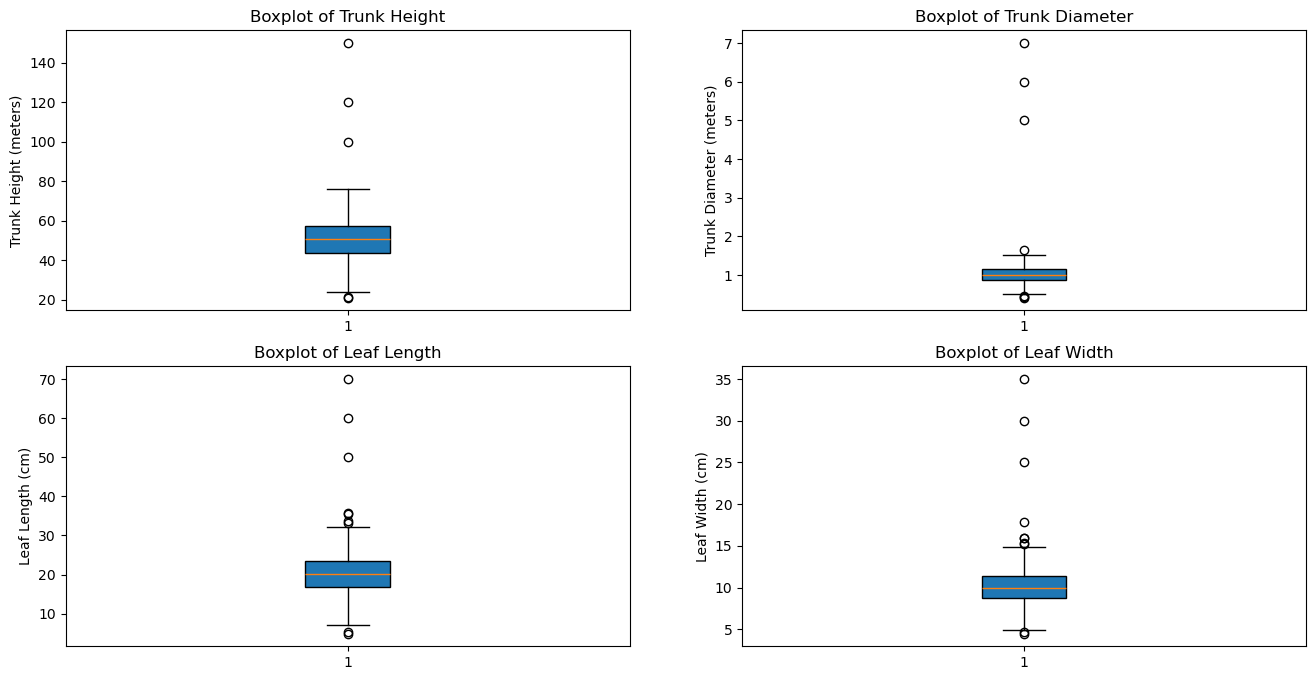

In [21]:
# Create boxplots to identify outliers
plt.figure(figsize=(16, 8))

# Trunk_Height boxplot
# patch_artist=True allows you to fill the inside of boxplots with color
plt.subplot(2, 2, 1)
plt.boxplot(df_trees['Trunk_Height'], patch_artist=True)
plt.title('Boxplot of Trunk Height')
plt.ylabel('Trunk Height (meters)')

# Trunk_Diameter boxplot
plt.subplot(2, 2, 2)
plt.boxplot(df_trees['Trunk_Diameter'], patch_artist=True)
plt.title('Boxplot of Trunk Diameter')
plt.ylabel('Trunk Diameter (meters)')

# Leaf_Length boxplot
plt.subplot(2, 2, 3)
plt.boxplot(df_trees['Leaf_Length'], patch_artist=True)
plt.title('Boxplot of Leaf Length')
plt.ylabel('Leaf Length (cm)')

# Leaf_Width boxplot
plt.subplot(2, 2, 4)
plt.boxplot(df_trees['Leaf_Width'], patch_artist=True)
plt.title('Boxplot of Leaf Width')
plt.ylabel('Leaf Width (cm)')


df_trees.describe()

The blue rectangles in your boxplot are called the interquartile range. This range represents the difference between the third quartile and the first quartile of a set of data values.

A standard rule in statistics is that any data point that falls beyond 1.5 times the blue boxes are considered outliers

In [23]:
#let's calculate the median first:
median_Leaf_Length = df_trees['Leaf_Length'].median() 
print(median_Leaf_Length)

20.1


In [24]:
#caluclate 25th percentile of leaf length
percentile25 = df_trees['Leaf_Length'].quantile(0.25)
print('percentile25 ', percentile25)

#caluclate 75th percentile of leaf length
percentile75 = df_trees['Leaf_Length'].quantile(0.75)
print('percentile75 ', percentile75)

percentile25  16.7825
percentile75  23.3525


In [25]:
#Calculate interquartile range
iqr = percentile75 - percentile25
print(iqr)

#**A standard rule in statistics is that any data point that falls beyond 1.5 times the blue boxes are considered outliers**

#calcualte upper and lower thresholds for outliers
upper_limit = percentile75 + 1.5 *iqr
lower_limit = percentile25 - 1.5 * iqr

#print upper and lower limit:
print ('Upper limit is: ' + str(upper_limit))
print ('Lower limit is: ' + str(lower_limit))

6.57
Upper limit is: 33.207499999999996
Lower limit is: 6.927499999999998


In [26]:
#isolate outliers on low end
df_lower = df_trees[df_trees['Leaf_Length'] < lower_limit]
#now we can see the outliers
df_lower


,Species,Leaf_Color,Trunk_Height,Trunk_Diameter,Leaf_Length,Leaf_Width
53,Bigleaf_Mahogany,Green,43.19,0.88,5.3,14.73
106,Spanish_Cedar,Green,67.28,0.93,4.9,11.84


In [27]:
outliers_lower = df_lower['Leaf_Length'].tolist()
outliers_lower

[5.3, 4.9]

In [28]:
df_trees['Leaf_Length'].replace(outliers_lower, median_Leaf_Length, inplace=True)

C:\Users\mq10006855\AppData\Local\Temp\ipykernel_14360\1375046741.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_trees['Leaf_Length'].replace(outliers_lower, median_Leaf_Length, inplace=True)


# repeat this for upper limit

In [30]:
#isolate outliers on upper end
df_upper = df_trees[df_trees['Leaf_Length'] > upper_limit]
#now we can see the outliers
df_upper

,Species,Leaf_Color,Trunk_Height,Trunk_Diameter,Leaf_Length,Leaf_Width
16,Brazil_Nut,Purple,54.40,0.97,33.22,10.45
39,Diesel,Brown,54.57,1.08,35.69,10.48
117,Spanish_Cedar,Purple,65.74,0.68,33.80,9.41
253,Spanish_Cedar,Yellow,52.81,0.93,70.00,11.16
328,Diesel,Purple,50.34,1.20,50.00,10.48
387,Diesel,Green,41.02,0.68,35.55,6.45
491,Bigleaf_Mahogany,Brown,47.49,1.03,60.00,12.51


In [31]:
outliers = df_upper['Leaf_Length'].tolist()
outliers

df_trees['Leaf_Length'].replace(outliers, median_Leaf_Length, inplace=True)

C:\Users\mq10006855\AppData\Local\Temp\ipykernel_14360\785307286.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_trees['Leaf_Length'].replace(outliers, median_Leaf_Length, inplace=True)


# inplace=True, the method modifies the original DataFrame or Series directly.

# let's double check if the outliers are fixed

,Trunk_Height,Trunk_Diameter,Leaf_Length,Leaf_Width
count,500.000000,500.000000,500.000000,500.000000
mean,51.032680,1.042000,19.942220,10.173880
std,11.611413,0.437061,4.632039,2.530627
min,21.040000,0.420000,6.980000,4.500000
25%,43.707500,0.880000,16.835000,8.750000
50%,50.620000,1.000000,20.100000,9.960000
75%,57.115000,1.150000,23.235000,11.340000
max,150.000000,7.000000,32.060000,35.000000


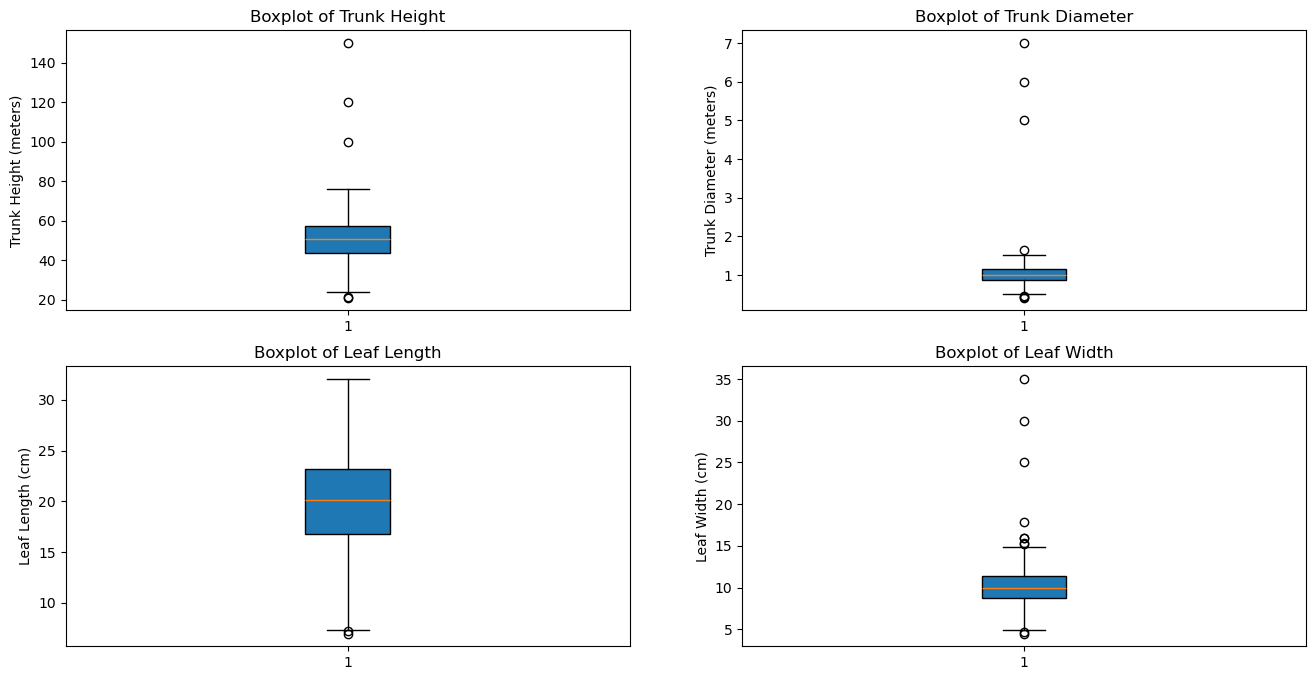

In [34]:
# Create boxplots to identify outliers
plt.figure(figsize=(16, 8))

# Trunk_Height boxplot
plt.subplot(2, 2, 1)
plt.boxplot(df_trees['Trunk_Height'], patch_artist=True)
plt.title('Boxplot of Trunk Height')
plt.ylabel('Trunk Height (meters)')

# Trunk_Diameter boxplot
plt.subplot(2, 2, 2)
plt.boxplot(df_trees['Trunk_Diameter'], patch_artist=True)
plt.title('Boxplot of Trunk Diameter')
plt.ylabel('Trunk Diameter (meters)')

# Leaf_Length boxplot
plt.subplot(2, 2, 3)
plt.boxplot(df_trees['Leaf_Length'], patch_artist=True)
plt.title('Boxplot of Leaf Length')
plt.ylabel('Leaf Length (cm)')

# Leaf_Width boxplot
plt.subplot(2, 2, 4)
plt.boxplot(df_trees['Leaf_Width'], patch_artist=True)
plt.title('Boxplot of Leaf Width')
plt.ylabel('Leaf Width (cm)')

#plt.tight_layout()

df_trees.describe()

In [35]:
#save the files back into directory/folder
df_trees.to_csv('trees_clean_Leaf_Length.csv', index=False)

# skewness

Text(0, 0.5, 'Leaf Width (cm)')

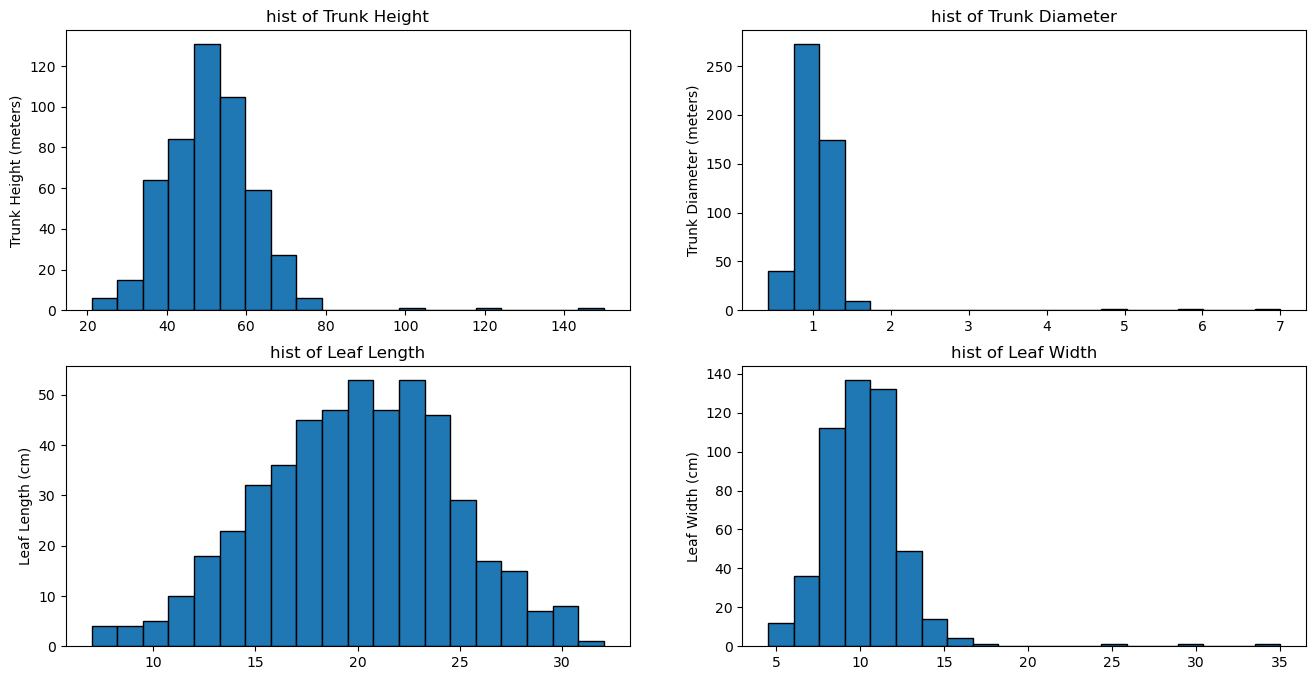

In [70]:
# Create boxplots to identify outliers
plt.figure(figsize=(16, 8))

# Trunk_Height boxplot
plt.subplot(2, 2, 1)
plt.hist(df_trees['Trunk_Height'], bins=20, edgecolor='black')
plt.title('Histogram of Trunk Height')
plt.ylabel('Trunk Height (meters)')

# Trunk_Diameter boxplot
plt.subplot(2, 2, 2)
plt.hist(df_trees['Trunk_Diameter'], bins=20, edgecolor='black')
plt.title('Histogram of Trunk Diameter')
plt.ylabel('Trunk Diameter (meters)')

# Leaf_Length boxplot
plt.subplot(2, 2, 3)
plt.hist(df_trees['Leaf_Length'], bins=20, edgecolor='black')
plt.title('Histogram of Leaf Length')
plt.ylabel('Leaf Length (cm)')

# Leaf_Width boxplot
plt.subplot(2, 2, 4)
plt.hist(df_trees['Leaf_Width'], bins=20, edgecolor='black')
plt.title('Histogram of Leaf Width')
plt.ylabel('Leaf Width (cm)')



In [ ]:
# in the above histogram, since we fixed th eoutliers of Leaf Lentgh, the distribution also shown normal

In [76]:
df_trees.skew(numeric_only=True)

Trunk_Height      1.692651
Trunk_Diameter    9.485408
Leaf_Length      -0.153052
Leaf_Width        3.266775
dtype: float64

In [78]:
df_trees['Leaf_Length'].skew()

-0.15305169229634225